# BÁO CÁO PHẦN 1 - BÀI 2 (TRANG 28): BANK MARKETING DATASET
## CÂU 3: Khảo sát mối liên hệ giữa các thuộc tính nhân khẩu học với quyết định gửi tiền (y)
- Khảo sát các biến: Nghề nghiệp (`job`), Tình trạng hôn nhân (`marital`), Trình độ học vấn (`education`) và Độ tuổi (`age`)
- Vẽ các biểu đồ trực quan hóa và đưa ra nhận xét


Họ tên: Hoàng Thành Đạt - MSSV: 6451071016


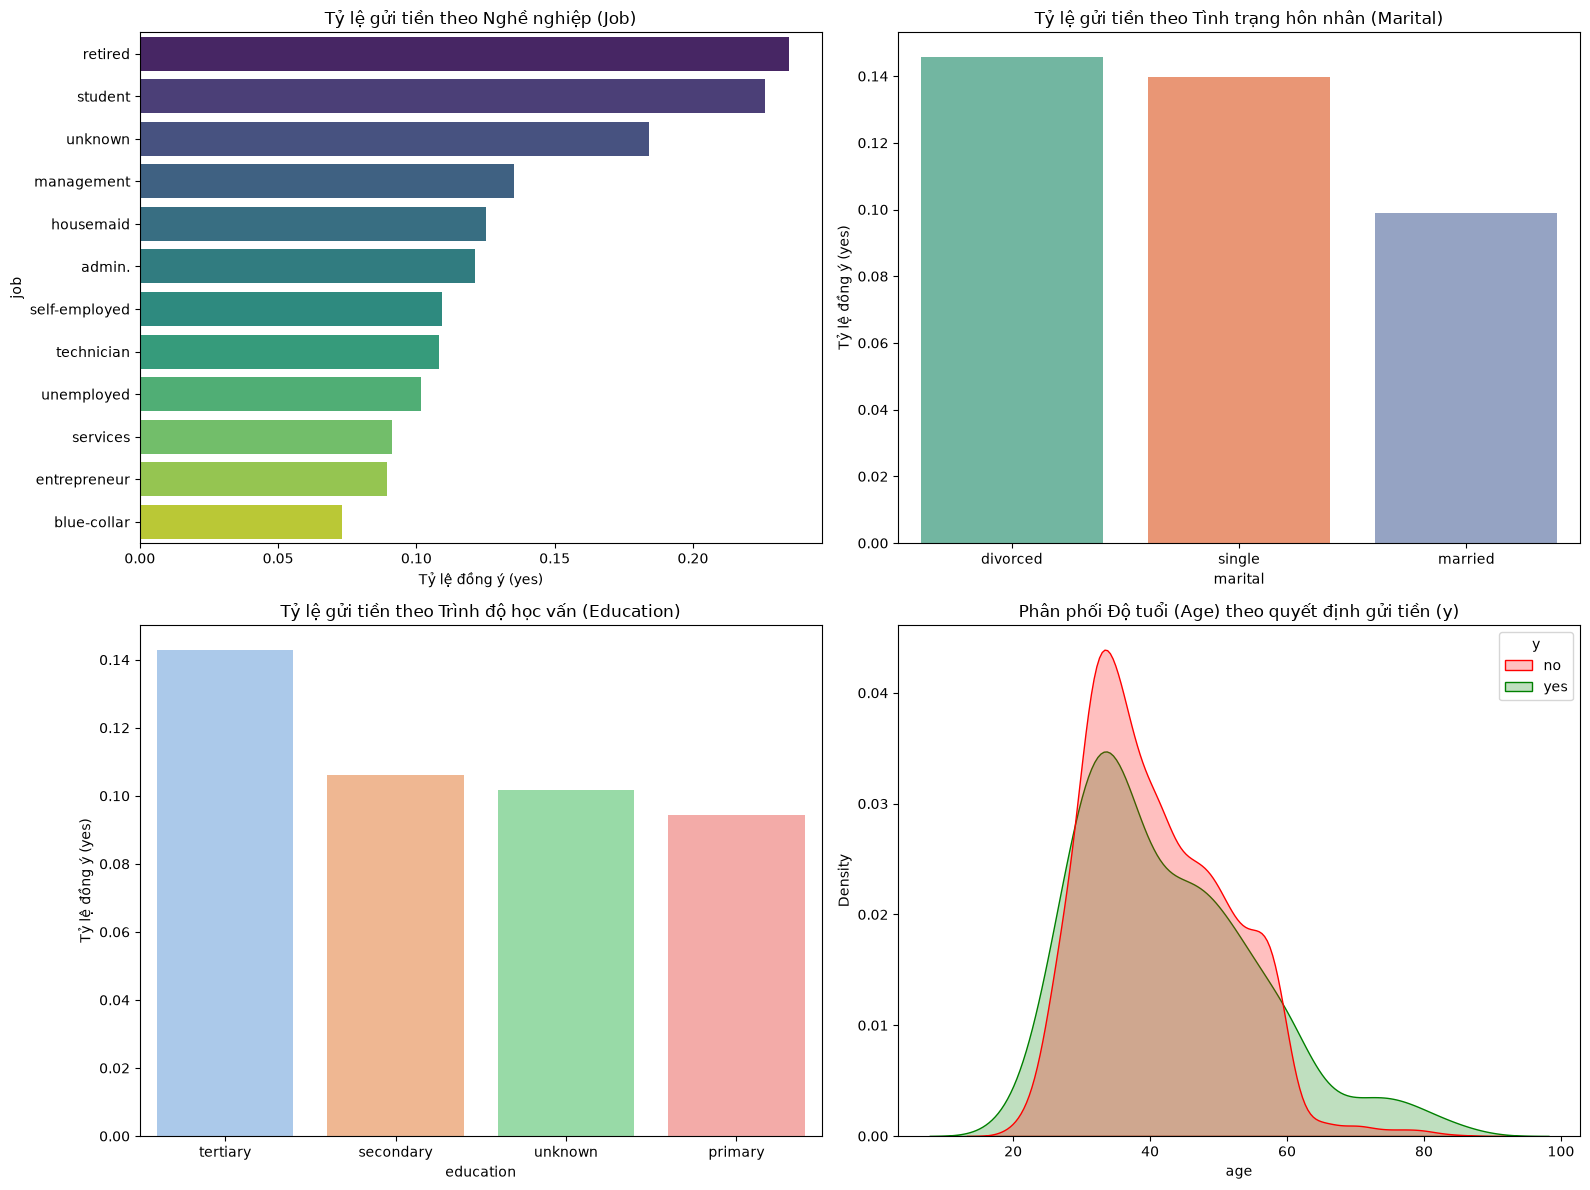

In [1]:
# ==========================================
# THÔNG TIN SINH VIÊN THỰC HIỆN
# Họ và tên: Hoàng Thành Đạt
# MSSV: 6451071016
# ==========================================
ho_ten = "Hoàng Thành Đạt"
mssv = "6451071016"
print(f"Họ tên: {ho_ten} - MSSV: {mssv}")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def get_data_path(rel_filename):
    for candidate in [
        os.path.join("..", "..", "dataset", rel_filename),
        os.path.join("..", "dataset", rel_filename),
        os.path.join("dataset", rel_filename),
        rel_filename
    ]:
        if os.path.exists(candidate):
            return candidate
    return rel_filename


path = get_data_path(os.path.join('bank', 'bank.csv'))
if not os.path.exists(path):
    path = get_data_path('bank.csv')

df = pd.read_csv(path, sep=';')
df['target'] = (df['y'] == 'yes').astype(int)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Tỷ lệ đăng ký theo Nghề nghiệp (Job)
job_rate = df.groupby('job')['target'].mean().sort_values(ascending=False).reset_index()
sns.barplot(data=job_rate, x='target', y='job', ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title("Tỷ lệ gửi tiền theo Nghề nghiệp (Job)")
axes[0, 0].set_xlabel("Tỷ lệ đồng ý (yes)")

# 2. Tỷ lệ đăng ký theo Tình trạng hôn nhân (Marital)
marital_rate = df.groupby('marital')['target'].mean().sort_values(ascending=False).reset_index()
sns.barplot(data=marital_rate, x='marital', y='target', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title("Tỷ lệ gửi tiền theo Tình trạng hôn nhân (Marital)")
axes[0, 1].set_ylabel("Tỷ lệ đồng ý (yes)")

# 3. Tỷ lệ đăng ký theo Trình độ học vấn (Education)
edu_rate = df.groupby('education')['target'].mean().sort_values(ascending=False).reset_index()
sns.barplot(data=edu_rate, x='education', y='target', ax=axes[1, 0], palette='pastel')
axes[1, 0].set_title("Tỷ lệ gửi tiền theo Trình độ học vấn (Education)")
axes[1, 0].set_ylabel("Tỷ lệ đồng ý (yes)")

# 4. Phân phối Độ tuổi (Age) theo quyết định y
sns.kdeplot(data=df, x='age', hue='y', common_norm=False, fill=True, ax=axes[1, 1], palette=['red', 'green'])
axes[1, 1].set_title("Phân phối Độ tuổi (Age) theo quyết định gửi tiền (y)")

plt.tight_layout()
plt.show()


### Nhận xét Câu 3:
- **Nghề nghiệp (`job`)**: Nhóm học sinh/sinh viên (`student`) và người về hưu (`retired`) có tỷ lệ đồng ý gửi tiền có kỳ hạn cao nhất (> 20-25%). Nhóm lao động chân tay (`blue-collar`) có tỷ lệ đồng ý thấp nhất.
- **Hôn nhân (`marital`)**: Khách hàng độc thân (`single`) có tỷ lệ đăng ký cao hơn (~14%) so với nhóm đã ly hôn (`divorced`) và đã kết hôn (`married`).
- **Học vấn (`education`)**: Trình độ học vấn tỷ lệ thuận với khả năng gửi tiền: nhóm tốt nghiệp đại học/sau đại học (`tertiary`) có tỷ lệ gửi tiền cao nhất.
- **Độ tuổi (`age`)**: Nhóm thanh niên trẻ (< 25 tuổi) và nhóm người cao tuổi (> 60 tuổi) có xu hướng đồng ý gửi tiết kiệm cao hơn rõ rệt so với độ tuổi lao động trung niên.
